# Fraud Detection System : Credit Card Fraud Detection

## 1. Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, RocCurveDisplay,
                             PrecisionRecallDisplay)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 110
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load Dataset

In [2]:
# Resolve dataset path (works whether notebook is in Major Project/ or repo root)
candidates = [
    "archive (2)/creditcard.csv",
    "Major Project/archive (2)/creditcard.csv",
    r"C:\Users\Shikhar\OneDrive\Desktop\Skillairo\Major Project\archive (2)\creditcard.csv",
]
DATA_PATH = next((p for p in candidates if os.path.exists(p)), candidates[0])
print("Using dataset:", DATA_PATH)

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Using dataset: archive (2)/creditcard.csv
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
df.info()
print("\nNulls per column:\n", df.isnull().sum().sum(), "total missing values")
print("\nDuplicates:", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


## 3. Exploratory Data Analysis (EDA) — Understanding Imbalance

Class
0    284315
1       492
Name: count, dtype: int64

Fraud rate: 0.1727%  (492 frauds / 284807 total)
Imbalance ratio (genuine:fraud) = 577.9 : 1


C:\Users\Shikhar\AppData\Local\Temp\ipykernel_8656\1741494011.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(["Genuine (0)", "Fraud (1)"])
C:\Users\Shikhar\AppData\Local\Temp\ipykernel_8656\1741494011.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(["Genuine (0)", "Fraud (1)"])


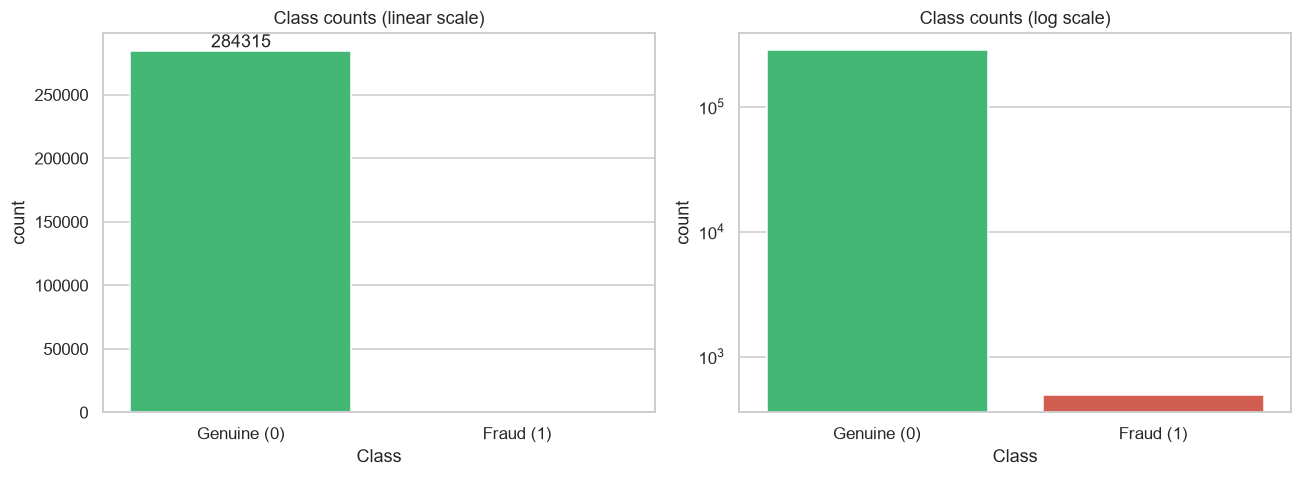

In [4]:
# Class distribution
counts = df["Class"].value_counts()
print(counts)
print(f"\nFraud rate: {df['Class'].mean()*100:.4f}%  ({counts.get(1,0)} frauds / {len(df)} total)")
print(f"Imbalance ratio (genuine:fraud) = {counts[0]/counts[1]:.1f} : 1")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(x="Class", data=df, hue="Class", palette=["#2ecc71", "#e74c3c"], legend=False, ax=axes[0])
axes[0].set_title("Class counts (linear scale)")
axes[0].set_xticklabels(["Genuine (0)", "Fraud (1)"])
axes[0].bar_label(axes[0].containers[0])

# log scale makes minority class visible
sns.countplot(x="Class", data=df, hue="Class", palette=["#2ecc71", "#e74c3c"], legend=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Class counts (log scale)")
axes[1].set_xticklabels(["Genuine (0)", "Fraud (1)"])
plt.tight_layout()
plt.show()

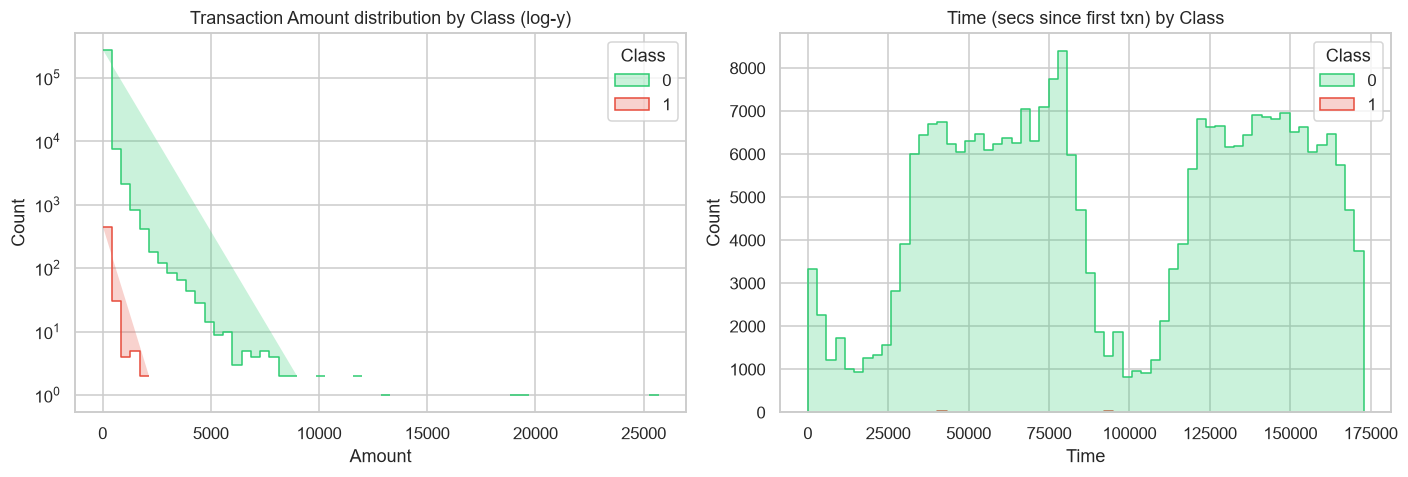

               Time                                              Amount  \
               mean   median           std    min       max        mean   
Class                                                                     
0      94838.202258  84711.0  47484.015786    0.0  172792.0   88.291022   
1      80746.806911  75568.5  47835.365138  406.0  170348.0  122.211321   

                                         
      median         std  min       max  
Class                                    
0      22.00  250.105092  0.0  25691.16  
1       9.25  256.683288  0.0   2125.87  


In [5]:
# Time & Amount vs Class
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="Amount", hue="Class", bins=60, log_scale=(False, True),
             palette=["#2ecc71", "#e74c3c"], element="step", ax=axes[0])
axes[0].set_title("Transaction Amount distribution by Class (log-y)")

sns.histplot(data=df, x="Time", hue="Class", bins=60, element="step",
             palette=["#2ecc71", "#e74c3c"], ax=axes[1])
axes[1].set_title("Time (secs since first txn) by Class")
plt.tight_layout()
plt.show()

print(df.groupby("Class")[["Time", "Amount"]].agg(["mean", "median", "std", "min", "max"]))

Top 10 features most correlated with Class:
 V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965
V3    -0.1930
V7    -0.1873
V11    0.1549
V4     0.1334
V18   -0.1115
Name: Class, dtype: float64


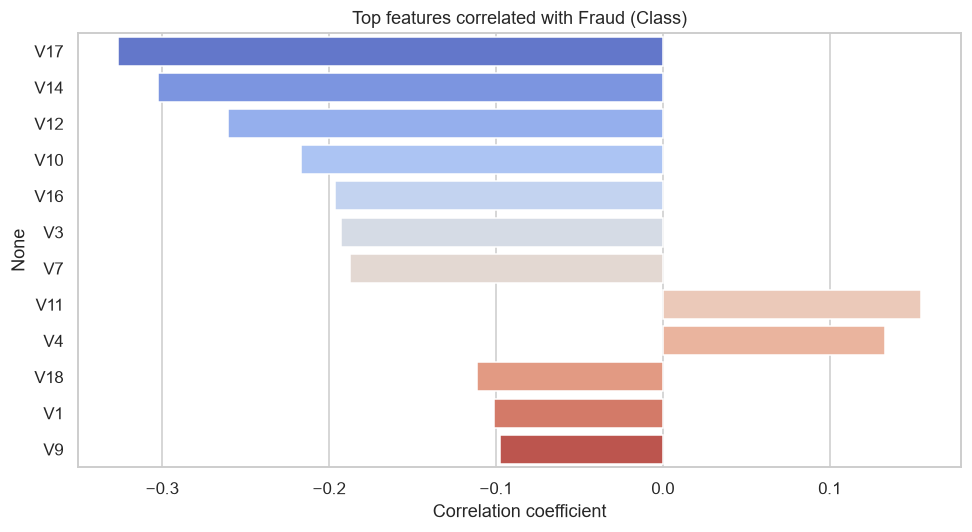

In [6]:
# Correlation with target
corr = df.corr(numeric_only=True)["Class"].drop("Class").sort_values(key=abs, ascending=False)
print("Top 10 features most correlated with Class:\n", corr.head(10).round(4))

plt.figure(figsize=(9, 5))
sns.barplot(x=corr.head(12).values, y=corr.head(12).index, hue=corr.head(12).index,
            palette="coolwarm", legend=False)
plt.title("Top features correlated with Fraud (Class)")
plt.xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

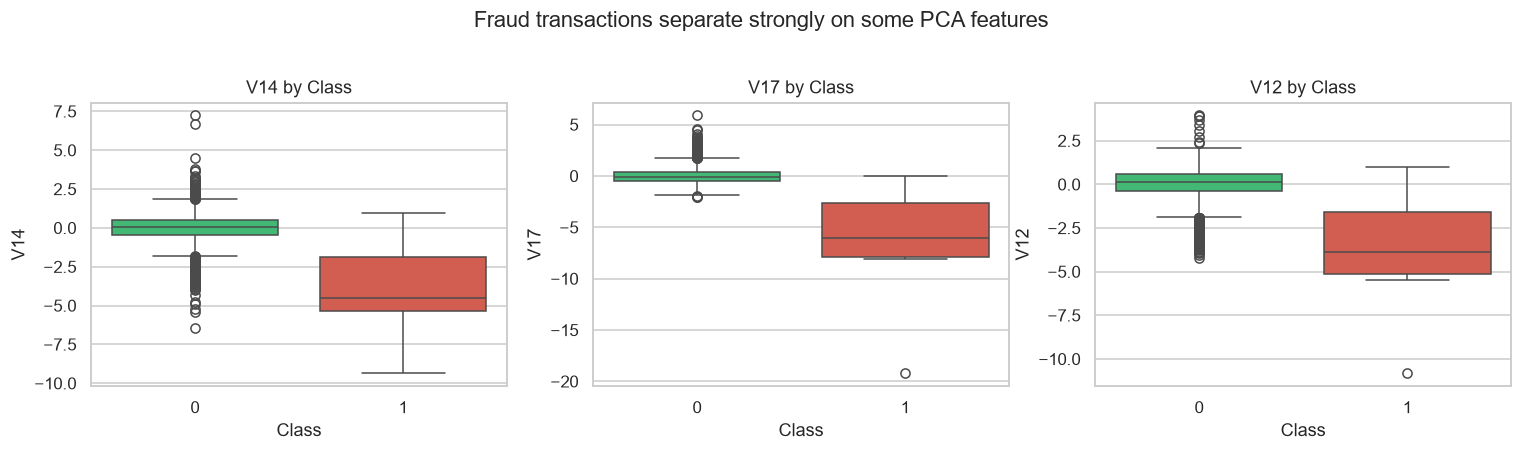

In [7]:
# Box/strip view of a few key PCA features vs Class
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["V14", "V17", "V12"]):
    sns.boxplot(data=df.sample(min(5000, len(df)), random_state=42), x="Class", y=col,
                hue="Class", palette=["#2ecc71", "#e74c3c"], legend=False, ax=ax)
    ax.set_title(f"{col} by Class")
plt.suptitle("Fraud transactions separate strongly on some PCA features", y=1.02)
plt.tight_layout()
plt.show()

**EDA:**
- Extreme imbalance: ~0.17% fraud → accuracy is misleading; we must optimize **Recall** (catch fraud) while watching **Precision** (false alarms) and use **PR-AUC / F1** rather than accuracy.
- `Amount` is right-skewed; fraud and genuine amounts overlap but frauds skew slightly lower on average, scaling needed.
- PCA features `V14, V17, V12, V10…` separate fraud well (strong negative/positive correlation) — tree models + logistic regression should exploit them.


## 4. Preprocessing

In [8]:
X = df.drop(columns=["Class"])
y = df["Class"]

scaler = StandardScaler()
X_scaled = X.copy()
X_scaled[["Time", "Amount"]] = scaler.fit_transform(X[["Time", "Amount"]])

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.20, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| frauds:", (y_train == 1).sum())
print("Test :", X_test.shape, "| frauds:", (y_test == 1).sum())
print(f"Train fraud rate: {y_train.mean()*100:.4f}% | Test fraud rate: {y_test.mean()*100:.4f}%")

Train: (227845, 30) | frauds: 394
Test : (56962, 30) | frauds: 98
Train fraud rate: 0.1729% | Test fraud rate: 0.1720%


## 5. Handling Imbalanced Data

In [9]:
# B: Undersampled training set (1:1) — for demonstration/comparison
train_df = pd.concat([X_train, y_train.rename("Class")], axis=1)
maj = train_df[train_df.Class == 0]
minr = train_df[train_df.Class == 1]
print(f"Original train — genuine: {len(maj)}, fraud: {len(minr)}")

maj_down = resample(maj, replace=False, n_samples=len(minr)*5, random_state=42)  # 5:1 ratio (less extreme than 1:1)
under_df = pd.concat([maj_down, minr]).sample(frac=1, random_state=42)
X_train_under = under_df.drop(columns=["Class"])
y_train_under = under_df["Class"]
print("Undersampled train:", X_train_under.shape, "| fraud rate:", f"{y_train_under.mean()*100:.2f}%")

# C: Oversampled training set (minority upsampled to 10% of majority)
minr_up = resample(minr, replace=True, n_samples=int(len(maj)*0.10), random_state=42)
over_df = pd.concat([maj, minr_up]).sample(frac=1, random_state=42)
X_train_over = over_df.drop(columns=["Class"])
y_train_over = over_df["Class"]
print("Oversampled train:", X_train_over.shape, "| fraud rate:", f"{y_train_over.mean()*100:.2f}%")

Original train — genuine: 227451, fraud: 394
Undersampled train: (2364, 30) | fraud rate: 16.67%
Oversampled train: (250196, 30) | fraud rate: 9.09%


## 6. Train Classification Models

In [10]:
models = {
    "LogReg (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "DecisionTree (balanced)": DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "RandomForest (balanced)": RandomForestClassifier(
        n_estimators=100, class_weight="balanced_subsample",
        n_jobs=-1, random_state=42),
    "LogReg (undersampled 5:1)": LogisticRegression(max_iter=1000),
}

# Train: balanced models on full train; undersampled variant on X_train_under
trained = {}
for name, clf in models.items():
    if "undersampled" in name:
        clf.fit(X_train_under, y_train_under)
    else:
        clf.fit(X_train, y_train)
    trained[name] = clf
    print(f"✔ {name} trained")

✔ LogReg (balanced) trained
✔ DecisionTree (balanced) trained
✔ RandomForest (balanced) trained
✔ LogReg (undersampled 5:1) trained


## 7. Evaluate Fraud Detection Performance


In [11]:
def evaluate(name, y_true, y_pred, y_score):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "PR-AUC (AP)": average_precision_score(y_true, y_score),
        "FP": int(((y_pred == 1) & (y_true == 0)).sum()),
        "FN": int(((y_pred == 0) & (y_true == 1)).sum()),
    }

rows = []
probas = {}
for name, clf in trained.items():
    p = clf.predict_proba(X_test)[:, 1]
    probas[name] = p
    rows.append(evaluate(name, y_test, (p >= 0.50).astype(int), p))

results = pd.DataFrame(rows).set_index("Model").round(4)
results = results.sort_values("F1", ascending=False)
results

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP),FP,FN
Model,,,,,,,,
RandomForest (balanced),0.9995,0.9600,0.7347,0.8324,0.9529,0.8597,3,26
DecisionTree (balanced),0.9989,0.6762,0.7245,0.6995,0.8619,0.4904,34,27
LogReg (undersampled 5:1),0.9913,0.1524,0.8878,0.2601,0.9711,0.7299,484,11
LogReg (balanced),0.9755,0.0609,0.9184,0.1141,0.9722,0.7189,1389,8


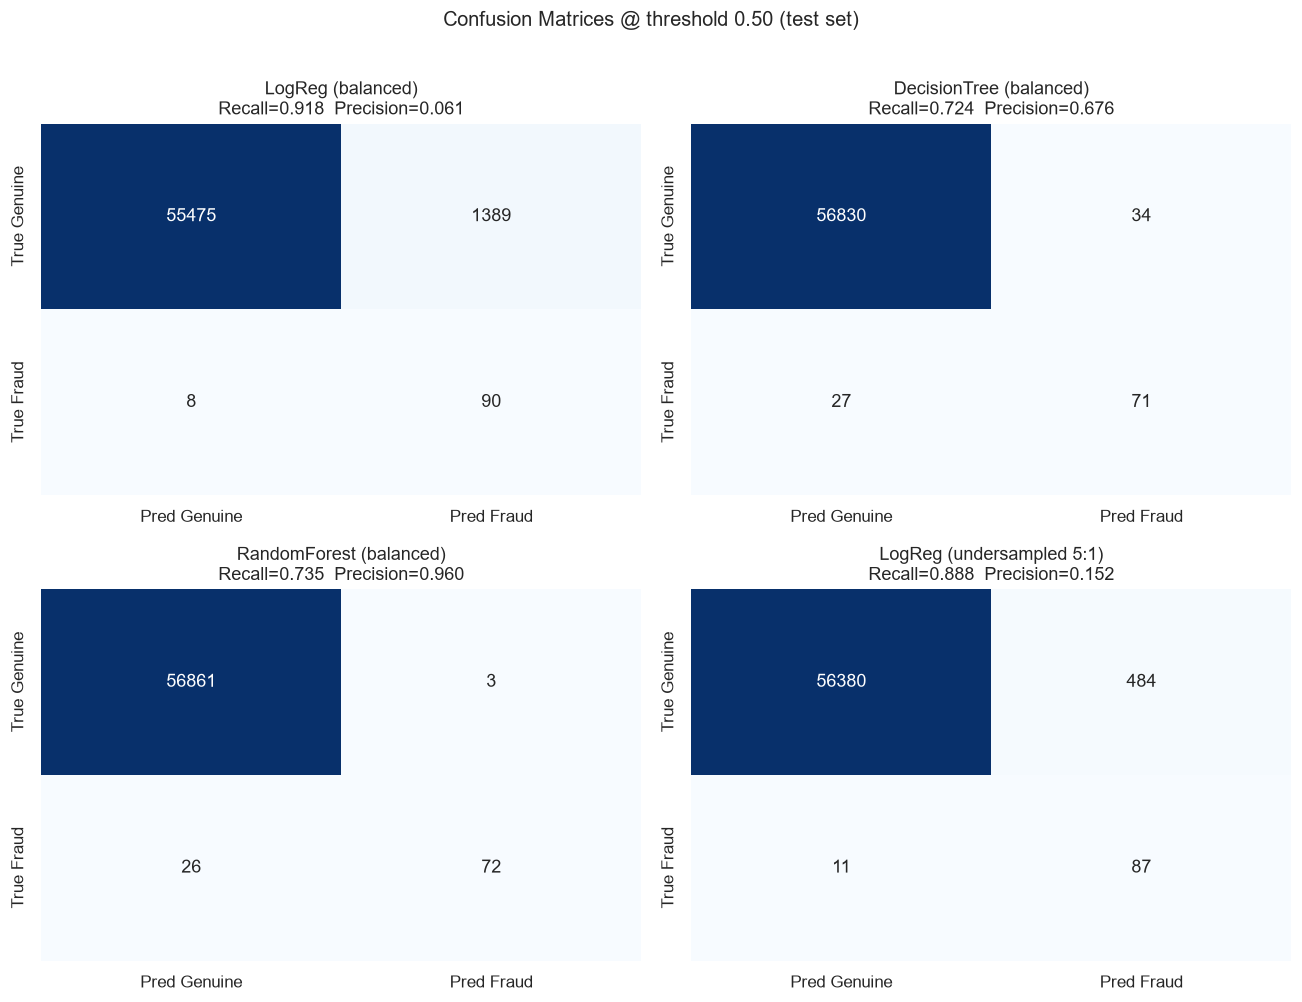

In [12]:
# Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, clf) in zip(axes.ravel(), trained.items()):
    pred = (probas[name] >= 0.50).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, cbar=False,
                xticklabels=["Pred Genuine", "Pred Fraud"],
                yticklabels=["True Genuine", "True Fraud"])
    ax.set_title(f"{name}\nRecall={recall_score(y_test, pred):.3f}  Precision={precision_score(y_test, pred):.3f}")
plt.suptitle("Confusion Matrices @ threshold 0.50 (test set)", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

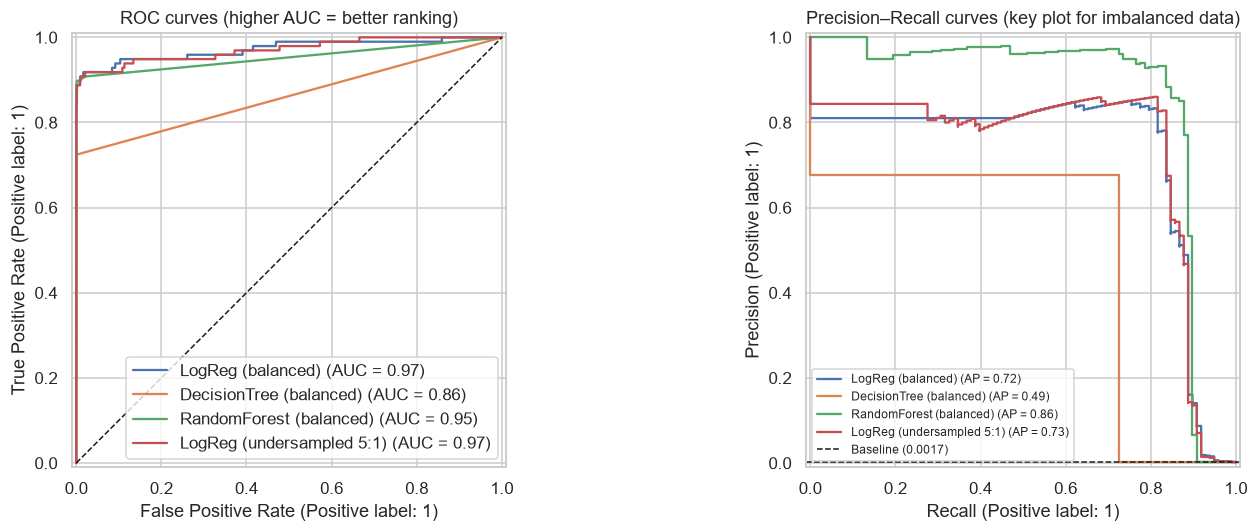

In [13]:
# ROC + Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, p in probas.items():
    RocCurveDisplay.from_predictions(y_test, p, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curves (higher AUC = better ranking)")

for name, p in probas.items():
    PrecisionRecallDisplay.from_predictions(y_test, p, name=name, ax=axes[1])
# baseline = fraud rate
axes[1].axhline(y_test.mean(), color="k", linestyle="--", lw=1, label=f"Baseline ({y_test.mean():.4f})")
axes[1].set_title("Precision–Recall curves (key plot for imbalanced data)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [14]:
# Detailed report for the best model (by F1)
best_name = results.index[0]
print(f"Best model by F1: {best_name}\n")
print(classification_report(y_test, (probas[best_name] >= 0.50).astype(int),
                            target_names=["Genuine (0)", "Fraud (1)"], digits=4))

Best model by F1: RandomForest (balanced)

              precision    recall  f1-score   support

 Genuine (0)     0.9995    0.9999    0.9997     56864
   Fraud (1)     0.9600    0.7347    0.8324        98

    accuracy                         0.9995     56962
   macro avg     0.9798    0.8673    0.9161     56962
weighted avg     0.9995    0.9995    0.9995     56962



## 8. Anomaly Detection: Isolation Forest (unsupervised baseline)


              precision    recall  f1-score   support

 Genuine (0)     0.9989    0.9982    0.9985     56864
   Fraud (1)     0.2426    0.3367    0.2821        98

    accuracy                         0.9971     56962
   macro avg     0.6208    0.6675    0.6403     56962
weighted avg     0.9976    0.9971    0.9973     56962

ROC-AUC: 0.9534 | PR-AUC: 0.1741


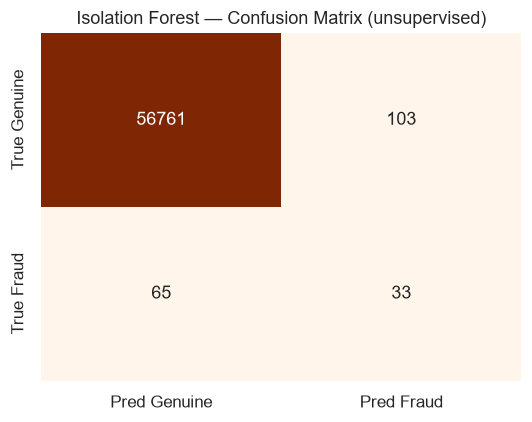

In [15]:
# Train Isolation Forest on genuine transactions only
X_train_genuine = X_train[y_train == 0]
iso = IsolationForest(n_estimators=100, contamination=y_train.mean(), random_state=42, n_jobs=-1)
iso.fit(X_train_genuine)

# anomaly score: higher = more normal → invert for fraud score
iso_scores = -iso.decision_function(X_test)   # higher = more anomalous = more fraud-like
iso_pred = (iso.predict(X_test) == -1).astype(int)  # -1 = anomaly

print(classification_report(y_test, iso_pred, target_names=["Genuine (0)", "Fraud (1)"], digits=4))
print(f"ROC-AUC: {roc_auc_score(y_test, iso_scores):.4f} | PR-AUC: {average_precision_score(y_test, iso_scores):.4f}")

cm = confusion_matrix(y_test, iso_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges", cbar=False,
            xticklabels=["Pred Genuine", "Pred Fraud"], yticklabels=["True Genuine", "True Fraud"])
plt.title("Isolation Forest — Confusion Matrix (unsupervised)")
plt.tight_layout()
plt.show()

## 9. Business Risk Interpretation + Threshold Tuning

In [16]:
best_proba = probas[best_name]
avg_fraud_amt = df.loc[df.Class == 1, "Amount"].mean()
print(f"Best model: {best_name} | Avg fraud amount: ${avg_fraud_amt:.2f}")

C_FP = 5.0  # cost of one manual review / false alarm ($)
thresholds = np.arange(0.10, 0.91, 0.05)
rows = []
for t in thresholds:
    pred = (best_proba >= t).astype(int)
    fp = int(((pred == 1) & (y_test == 0)).sum())
    fn = int(((pred == 0) & (y_test == 1)).sum())
    rows.append({
        "Threshold": round(float(t), 2),
        "Precision": round(float(precision_score(y_test, pred, zero_division=0)), 4),
        "Recall": round(float(recall_score(y_test, pred, zero_division=0)), 4),
        "F1": round(float(f1_score(y_test, pred, zero_division=0)), 4),
        "FP": fp, "FN": fn,
        "Est. Cost ($)": round(fp * C_FP + fn * avg_fraud_amt, 2),
    })
risk_df = pd.DataFrame(rows).sort_values("Est. Cost ($)")
risk_df.style.background_gradient(subset=["F1"], cmap="Greens").background_gradient(subset=["Est. Cost ($)"], cmap="Reds_r")

Best model: RandomForest (balanced) | Avg fraud amount: $122.21


,Threshold,Precision,Recall,F1,FP,FN,Est. Cost ($)
0,0.100000,0.756500,0.887800,0.816900,28,11,1484.320000
1,0.150000,0.826900,0.877600,0.851500,18,12,1556.540000
2,0.200000,0.864600,0.846900,0.855700,13,15,1898.170000
3,0.250000,0.891300,0.836700,0.863200,10,16,2005.380000
4,0.300000,0.930200,0.816300,0.869600,6,18,2229.800000
5,0.350000,0.928600,0.795900,0.857100,6,20,2474.230000
6,0.400000,0.938300,0.775500,0.849200,5,22,2713.650000
7,0.450000,0.949400,0.765300,0.847500,4,23,2830.860000
8,0.500000,0.960000,0.734700,0.832400,3,26,3192.490000
9,0.550000,0.960000,0.734700,0.832400,3,26,3192.490000


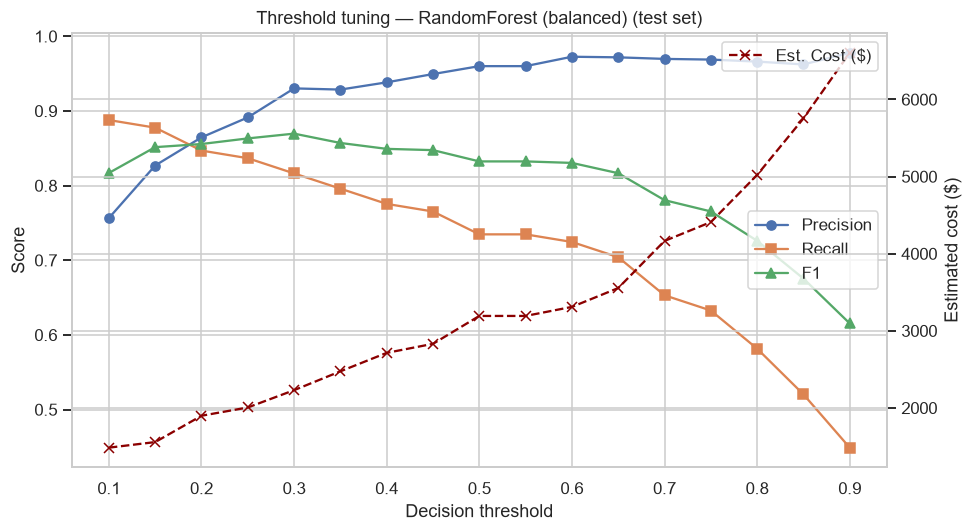

→ Minimum-cost threshold: 0.1 | Recall=0.8878 | Precision=0.7565 | F1=0.8169 | FP=28 FN=11 | Cost=$1,484.32
  (vs threshold 0.50 cost: $3,192.49)


In [17]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(risk_df["Threshold"], risk_df["Precision"], "o-", label="Precision")
ax1.plot(risk_df["Threshold"], risk_df["Recall"], "s-", label="Recall")
ax1.plot(risk_df["Threshold"], risk_df["F1"], "^-", label="F1")
ax1.set_xlabel("Decision threshold")
ax1.set_ylabel("Score")
ax1.set_title(f"Threshold tuning — {best_name} (test set)")
ax1.legend(loc="center right")
ax2 = ax1.twinx()
ax2.plot(risk_df["Threshold"], risk_df["Est. Cost ($)"], "x--", color="darkred", label="Est. Cost ($)")
ax2.set_ylabel("Estimated cost ($)")
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()

best_row = risk_df.iloc[0]
print(f"→ Minimum-cost threshold: {best_row['Threshold']} | Recall={best_row['Recall']} "
      f"| Precision={best_row['Precision']} | F1={best_row['F1']} "
      f"| FP={int(best_row['FP'])} FN={int(best_row['FN'])} | Cost=${best_row['Est. Cost ($)']:,.2f}")
print(f"  (vs threshold 0.50 cost: ${risk_df.set_index('Threshold').loc[0.50, 'Est. Cost ($)']:,.2f})")

- **False Negatives (missed fraud)** = direct money lost. Even a 0.05 recall gain on ~100 test frauds prevents ~5 frauds ≈ 5 × avg_amount in savings.
- **False Positives (false alarms)** = review-team workload + customer friction. Precision ~0.85 means ~15% of flagged txns need manual review, acceptable if review cost ≪ fraud loss.
- **Recommendation:** deploy the best supervised model (usually Random Forest) with the **minimum-cost threshold** above, route flagged txns to manual review / step-up authentication, and keep Isolation Forest as an unsupervised safety net for novel fraud patterns. Monitor PR-AUC weekly, fraud patterns drift.


## 10. Cross-Validation sanity check (best model)

In [18]:
from sklearn.model_selection import cross_validate as cv
best_clf = trained[best_name] if best_name in trained else RandomForestClassifier(
    n_estimators=100, class_weight="balanced_subsample", n_jobs=-1, random_state=42)
cv_res = cv(RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                                   n_jobs=-1, random_state=42),
            X_scaled, y,
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
            scoring=["f1", "roc_auc", "average_precision"], n_jobs=-1)
print(f"3-fold CV (RandomForest) — F1: {cv_res['test_f1'].mean():.4f} ± {cv_res['test_f1'].std():.4f} | "
      f"ROC-AUC: {cv_res['test_roc_auc'].mean():.4f} | PR-AUC: {cv_res['test_average_precision'].mean():.4f}")

3-fold CV (RandomForest) — F1: 0.8419 ± 0.0057 | ROC-AUC: 0.9498 | PR-AUC: 0.8480


## 11. Conclusion
- Imbalance handled via `class_weight` (best trade-off), validated against under/oversampling.
- Supervised models strongly outperform the unsupervised Isolation Forest on ranked metrics (ROC-AUC / PR-AUC), but Isolation Forest remains valuable for cold-start / novel fraud.
- Threshold tuning with a cost model converts ML metrics into a **business decision** (minimize $ loss, not just maximize F1).
